# Umsatzprognose mit Azure AutoML Endpoint

In diesem Notebook wird über einen **bereitgestellten Azure AutoML Endpoint** der tägliche Umsatz
(`total_revenue`) des Amazon-Sales-Datasets für mehrere Tage gleichzeitig vorhergesagt.
Die Ergebnisse werden anschliessend grafisch dargestellt.

**Ablauf:**
1. Historische Daten laden.
2. Endpoint-URL und Schlüssel laden.
3. Aufbau der Anfrage (Payload mit den zukünftigen Tagen).
4. Absetzen der Anfrage gegen den Endpoint.
5. Visualisierung der Vorhersagen zusammen mit der Historie.

In [1]:
# Benötigte Bibliotheken importieren
import json
import os
import urllib.error
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd
import plotly.graph_objects as go
from dotenv import load_dotenv

## Schritt 1: Historische Daten laden

`amazon_sales_daily.csv` enthält den Umsatz pro Tag (Summe aller Bestellungen eines Tages).
Mit genau diesen Daten wurde das AutoML-Modell trainiert.

In [2]:
df_hist = pd.read_csv("amazon_sales_daily.csv")
df_hist["order_date"] = pd.to_datetime(df_hist["order_date"])

df_hist.info()
df_hist.tail()

<class 'pandas.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_date     730 non-null    datetime64[us]
 1   total_revenue  730 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 11.5 KB


,order_date,total_revenue
725,2023-12-27,47903.98
726,2023-12-28,45239.63
727,2023-12-29,44012.05
728,2023-12-30,41963.50
729,2023-12-31,55757.38


## Schritt 2: Endpoint-URL und Schlüssel

Jeder Azure-Endpoint hat eine eigene URL und einen API-Schlüssel (Key).
- Die URL wird benötigt, um die Anfrage an die richtige Stelle zu senden.
- Der Key dient zur Authentifizierung.

Beide Werte stehen in der Datei `.env` (siehe `.env.example`). Diese Datei wird nicht auf GitHub hochgeladen,
damit der Key nicht öffentlich wird.

In [3]:
load_dotenv()

url = os.getenv("AZUREML_SCORING_URI")
api_key = os.getenv("AZUREML_API_KEY")

headers = {
    "Content-Type": "application/json",
    "Authorization": ("Bearer " + api_key),
}

## Schritt 3: Payload erstellen

Das Modell verwendet ausser dem Datum keine weiteren Features. Für die Vorhersage reicht es deshalb,
die **zukünftigen Tage direkt nach dem letzten historischen Datum** zu senden.

Jede Zeile in `data` steht für einen Tag. Die Anzahl Tage darf nicht grösser sein als der beim Training eingestellte Prognosehorizont.

In [4]:
horizont = 14  # Anzahl Tage, die vorhergesagt werden

letzter_tag = df_hist["order_date"].max()
zukunft = pd.date_range(letzter_tag + pd.Timedelta(days=1), periods=horizont, freq="D")

data = {
    "input_data": {
        "columns": ["order_date"],
        "index": list(range(len(zukunft))),
        "data": [[d.strftime("%Y-%m-%d")] for d in zukunft],
    }
}

print(json.dumps(data, indent=2)[:400])

{
  "input_data": {
    "columns": [
      "order_date"
    ],
    "index": [
      0,
      1,
      2,
      3,
      4,
      5,
      6,
      7,
      8,
      9,
      10,
      11,
      12,
      13
    ],
    "data": [
      [
        "2024-01-01"
      ],
      [
        "2024-01-02"
      ],
      [
        "2024-01-03"
      ],
      [
        "2024-01-04"
      ],
      [
        "202


## Schritt 4: Anfrage an den Endpoint senden

Die Daten werden an den Endpoint gesendet. Die Vorhersagen werden als JSON zurückgegeben
und in einen Pandas DataFrame umgewandelt.

In [5]:
body = str.encode(json.dumps(data))
req = urllib.request.Request(url, body, headers)

try:
    response = urllib.request.urlopen(req)
    result = response.read()
except urllib.error.HTTPError as error:
    print("Fehler, Status:", error.code)
    print(error.read().decode("utf8", "ignore"))
    raise

# Vorhersagen in Liste umwandeln
preds = json.loads(result.decode("utf-8"))

df = pd.DataFrame({"date": zukunft, "forecast": preds})
df

,date,forecast
0,2024-01-01,44773.113317
1,2024-01-02,45114.861995
2,2024-01-03,45069.003676
3,2024-01-04,44934.063431
4,2024-01-05,45870.977424
5,2024-01-06,44857.117648
6,2024-01-07,45312.509993
7,2024-01-08,45874.748045
8,2024-01-09,45613.558838
9,2024-01-10,46179.209715


## Schritt 5: Vorhersage darstellen

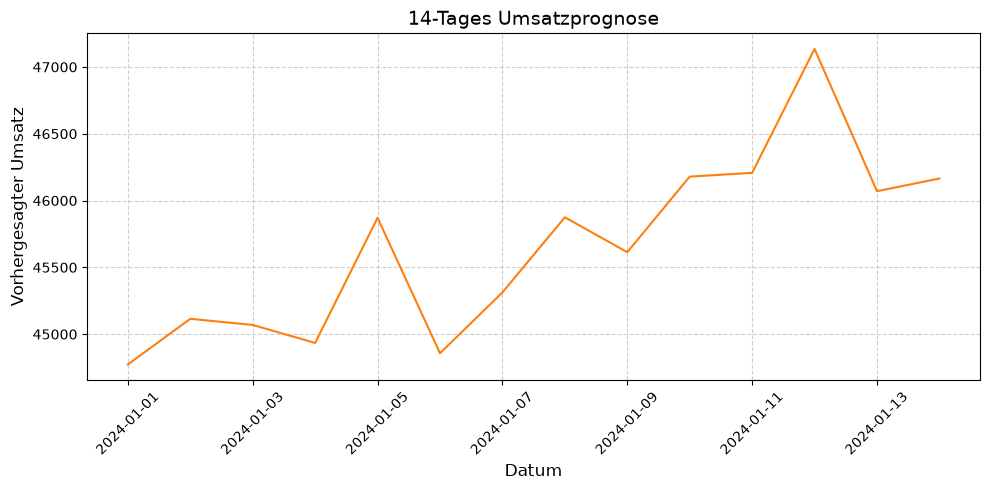

In [6]:
plt.figure(figsize=(10, 5))
plt.plot(df["date"], df["forecast"], linestyle="-", linewidth=1.5, color=plt.cm.tab10(1))
plt.title(f"{horizont}-Tages Umsatzprognose", fontsize=14)
plt.xlabel("Datum", fontsize=12)
plt.ylabel("Vorhergesagter Umsatz", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Schritt 6: Historie und Vorhersagen kombinieren

Die historischen Daten werden auf die letzten Tage vor der Prognose reduziert und die Vorhersagen
an das Ende der Historie angefügt. So ist der direkte Vergleich zwischen Vergangenheit und Prognose möglich.

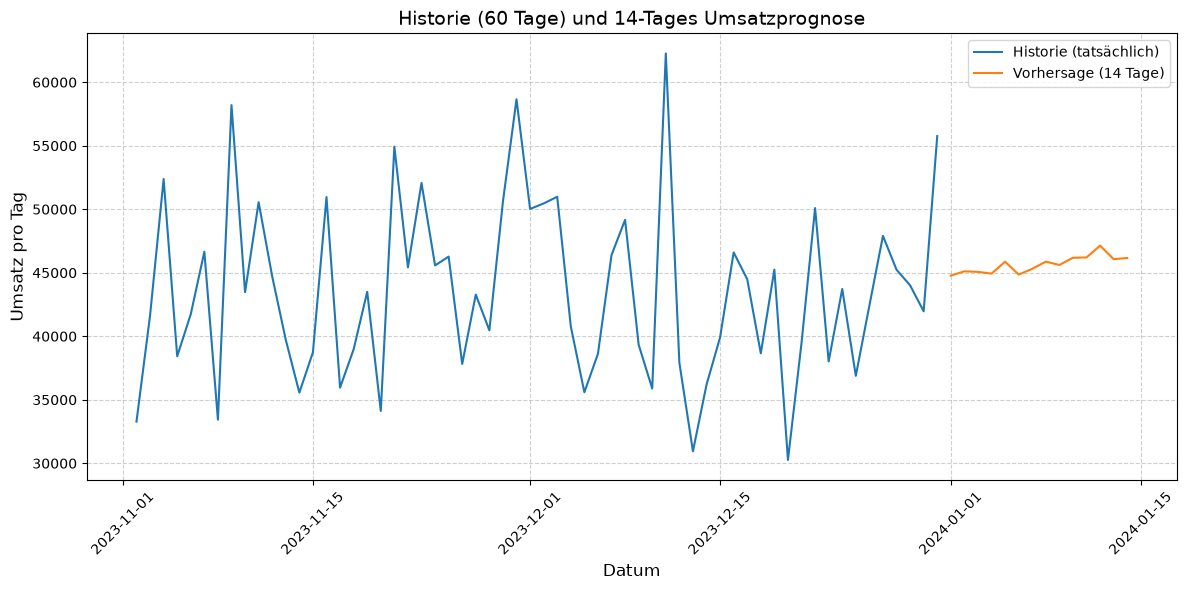

In [7]:
hist_window = 60  # Tage Historie vor Beginn der Vorhersage
first_forecast_date = df["date"].min()
df_hist_plot = df_hist[df_hist["order_date"] >= (first_forecast_date - pd.Timedelta(days=hist_window))]

plt.figure(figsize=(12, 6))
plt.plot(df_hist_plot["order_date"], df_hist_plot["total_revenue"], label="Historie (tatsächlich)", color="#1f77b4")
plt.plot(df["date"], df["forecast"], label=f"Vorhersage ({horizont} Tage)", color="#ff7f0e")

plt.title(f"Historie ({hist_window} Tage) und {horizont}-Tages Umsatzprognose", fontsize=14)
plt.xlabel("Datum", fontsize=12)
plt.ylabel("Umsatz pro Tag", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Dashboard: Historie und Vorhersage

Dieses Dashboard zeigt den **tatsächlichen Tagesumsatz** der letzten Tage (blaue Linie) und daneben die
**Vorhersage für die nächsten Tage** (orange Linie). Die interaktive Darstellung erlaubt es, hineinzuzoomen,
einzelne Werte abzulesen und die Legende an- oder auszuschalten.

In [8]:
fig = go.Figure()

# Historie (Blau)
fig.add_trace(go.Scatter(
    x=df_hist_plot["order_date"],
    y=df_hist_plot["total_revenue"],
    mode="lines",
    name="Historie (tatsächlich)",
    line=dict(color="#1f77b4", width=2),
))

# Vorhersage (Orange)
fig.add_trace(go.Scatter(
    x=df["date"],
    y=df["forecast"],
    mode="lines+markers",
    name=f"Vorhersage ({horizont} Tage)",
    line=dict(color="#ff7f0e", width=2),
    marker=dict(size=6),
))

fig.update_layout(
    title=f"Historie ({hist_window} Tage) und {horizont}-Tages Umsatzprognose",
    xaxis_title="Datum",
    yaxis_title="Umsatz pro Tag",
    template="plotly_white",
    legend=dict(x=0, y=1.1, orientation="h"),
    margin=dict(l=40, r=40, t=80, b=40),
)

fig.show()